<a href="https://colab.research.google.com/github/eeswepe/PCVK_GANJIL_2026/blob/main/week/7Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jobsheet Minggu 7 - Segmentasi Citra dengan Thresholding

## D. TUGAS PRAKTIKUM

### D1. Tugas Individu

1. Buka <https://colab.research.google.com/>. Setelah dipastikan bahwa google Colab terhubung
   dengan Github Anda, lanjutkan dengan memilih repository yang telah digunakan pada praktikum
   minggu lalu, rename file menjadi "Week7.ipynb".

   Kemudian import folder yang ada di Drive Anda dengan cara sebagai berikut

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2. Import beberapa library berikut yang akan digunakan selama uji coba praktikum minggu ke-7
berikut.

In [2]:
#Library yang digunakan
import os
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pylab as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

# Folder citra: pakai Google Drive bila tersedia (Colab), kalau tidak pakai folder lokal.
IMG_DIR = '/content/drive/MyDrive/pcvk/week7'
if not os.path.isdir(IMG_DIR):
    IMG_DIR = 'assets'
print('IMG_DIR :', IMG_DIR)

_berkas = ['gradient.jpg', 'sudoku-original.jpg', 'lena_gs_lc2.jpg', 'ktp_fulan.jpg']
for _n in _berkas:
    _p = os.path.join(IMG_DIR, _n)
    print('  %-22s %s' % (_n, 'ADA' if os.path.exists(_p) else 'TIDAK ADA'))


IMG_DIR : /content/drive/MyDrive/pcvk/week7
  gradient.jpg           ADA
  sudoku-original.jpg    ADA
  lena_gs_lc2.jpg        ADA
  ktp_fulan.jpg          ADA


3. Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan threshold = 200,
   **secara manual** sehingga menghasilkan tampilan seperti berikut:

Ketentuan:

| Jenis Global Threshold | Jika nilai piksel > thresh | Jika nilai piksel <= thresh |
|---|---|---|
| BINARY | Menjadi nilai maksimal | Menjadi 0 |
| BINARY_INV | Menjadi 0 | Menjadi nilai maksimal |
| TRUNC | Menjadi thresh | Nilai asli tetap |
| TOZERO | Nilai asli tetap | Menjadi 0 |
| TOZERO_INV | Menjadi 0 | Nilai asli tetap |

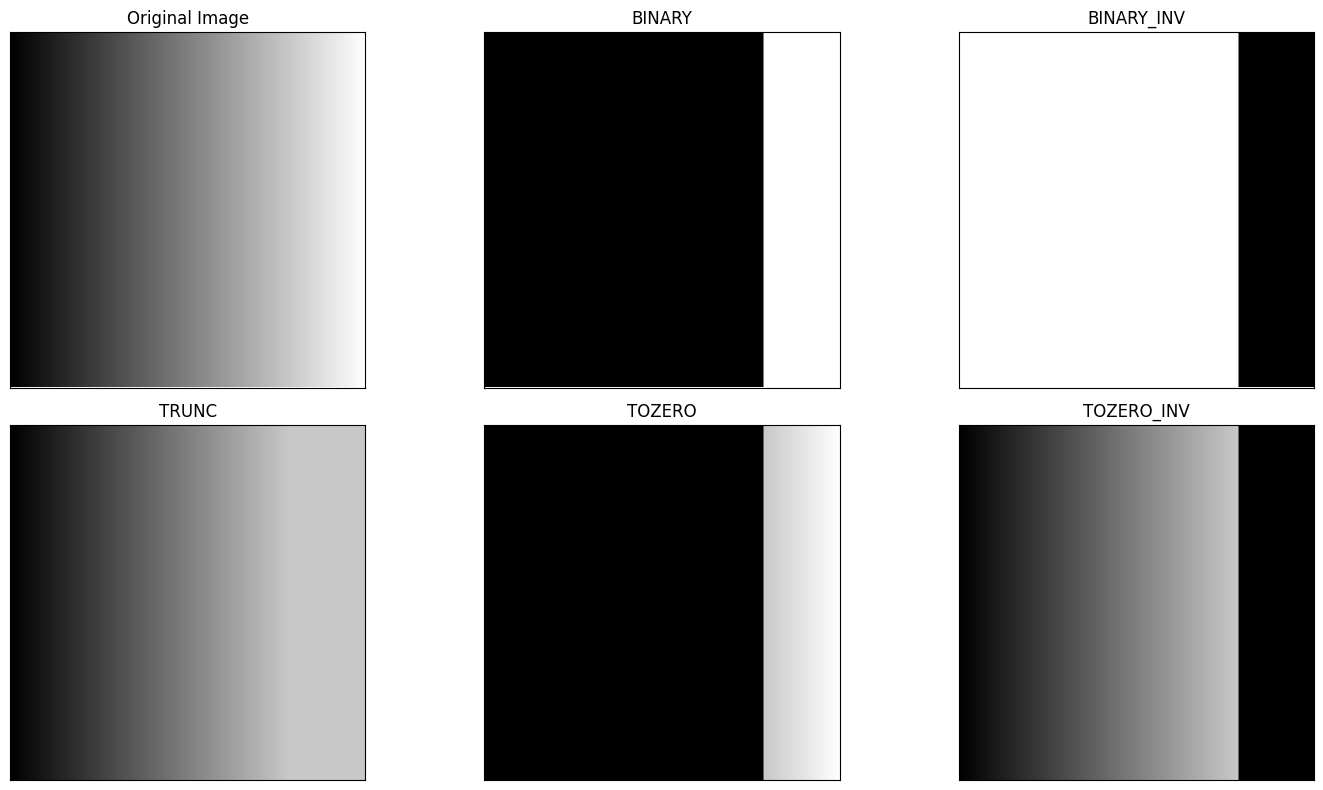

BINARY       min=  0 max=255
BINARY_INV   min=  0 max=255
TRUNC        min=  0 max=200
TOZERO       min=  0 max=255
TOZERO_INV   min=  0 max=200


In [3]:
def global_threshold_manual(gray, thresh, maxval, jenis):
    out = gray.copy()
    if jenis == 'BINARY':
        out[gray > thresh] = maxval
        out[gray <= thresh] = 0
    elif jenis == 'BINARY_INV':
        out[gray > thresh] = 0
        out[gray <= thresh] = maxval
    elif jenis == 'TRUNC':
        out[gray > thresh] = thresh
    elif jenis == 'TOZERO':
        out[gray <= thresh] = 0
    elif jenis == 'TOZERO_INV':
        out[gray > thresh] = 0
    return out

img = cv.imread(os.path.join(IMG_DIR, 'gradient.jpg'))
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

thresh = 200
maxval = 255
jenis_list = ['BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']

hasil = {}
for jenis in jenis_list:
    hasil[jenis] = global_threshold_manual(gray, thresh, maxval, jenis)

plt.figure(figsize=(15,8))
plt.subplot(2,3,1)
plt.imshow(gray, 'gray', vmin=0, vmax=255)
plt.title('Original Image')
plt.xticks([]), plt.yticks([])

for i, jenis in enumerate(jenis_list):
    plt.subplot(2,3,i+2)
    plt.imshow(hasil[jenis], 'gray', vmin=0, vmax=255)
    plt.title(jenis)
    plt.xticks([]), plt.yticks([])
plt.tight_layout(); plt.show()

for jenis in jenis_list:
    print('%-12s min=%3d max=%3d' % (jenis, hasil[jenis].min(), hasil[jenis].max()))

4. Buat program Adaptive Threshold: adaptive mean dan adaptive Gaussian **tanpa menggunakan**
   `cv.threshold()`, `cv.adaptiveThreshold()`, maupun fungsi filter siap pakai dengan menggunakan
   citra Sudoku yang memiliki pencahayaan tidak merata.

Ketentuan: global threshold secara manual dengan ambang 127, ukuran jendela 11 x 11, C = 2, dan
sigma = 2 untuk Gaussian sehingga menghasilkan tampilan seperti berikut.

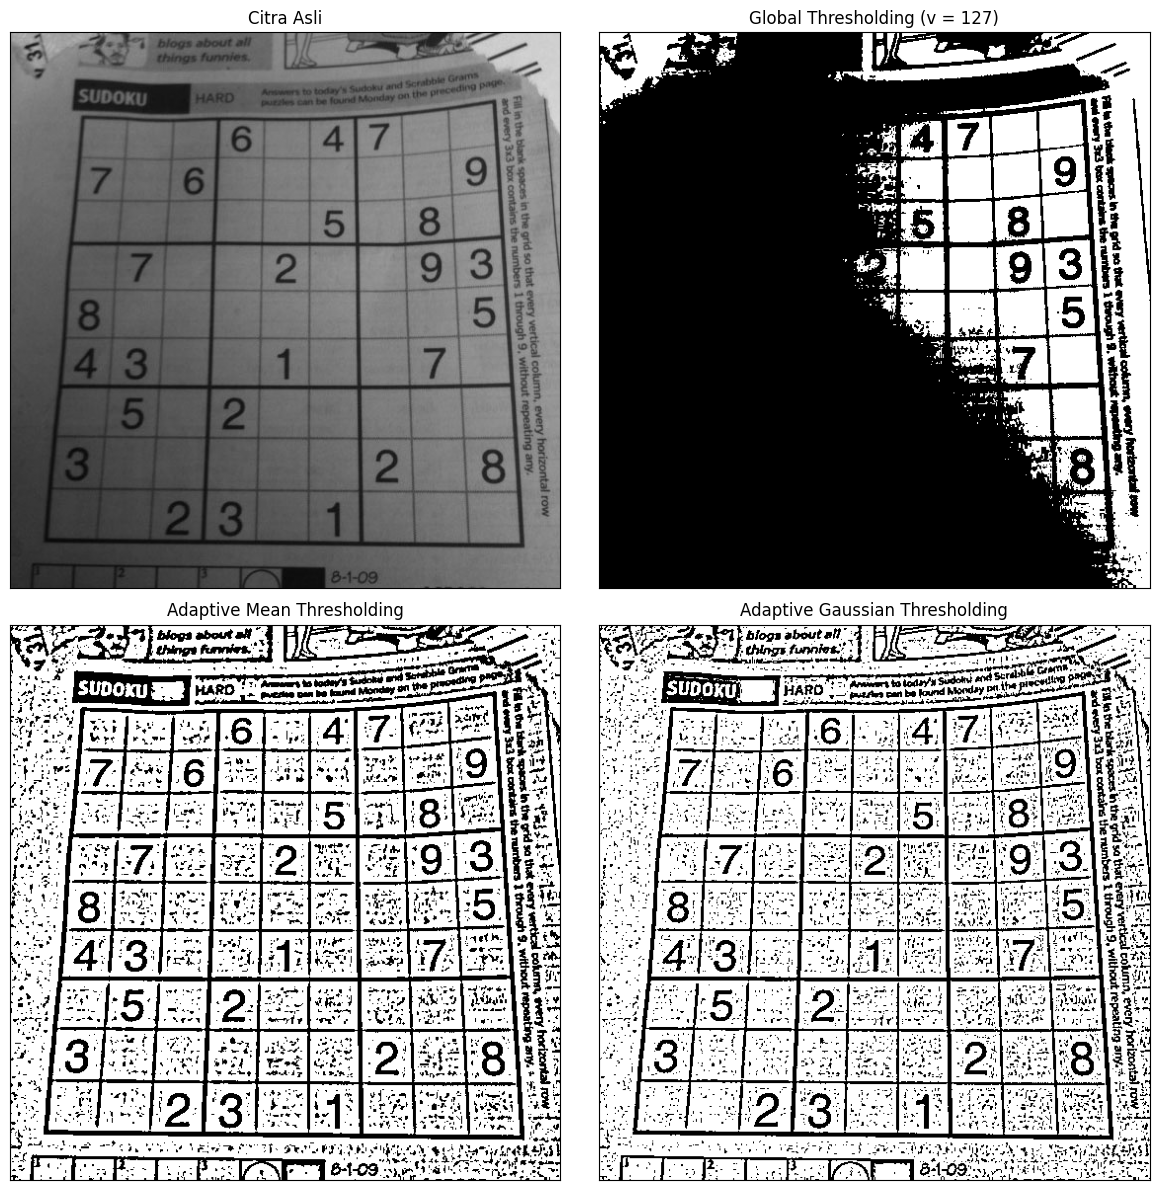

Piksel putih global 127    : 81788
Piksel putih adaptive mean : 233927
Piksel putih adaptive gauss: 243951


In [4]:
def box_mean_filter(img, block):
    # rata-rata jendela block x block memakai integral image (tanpa fungsi filter pustaka)
    r = block // 2
    p = np.pad(img.astype(np.float64), r, mode='edge')
    ii = np.cumsum(np.cumsum(p, axis=0), axis=1)
    ii = np.pad(ii, ((1, 0), (1, 0)))
    H, W = img.shape
    S = ii[block:block+H, block:block+W] - ii[0:H, block:block+W] - ii[block:block+H, 0:W] + ii[0:H, 0:W]
    return S / float(block * block)

def gaussian_kernel_1d(n, sigma):
    a = np.arange(n) - n // 2
    g = np.exp(-(a.astype(np.float64) ** 2) / (2.0 * sigma ** 2))
    return g / g.sum()

def convolve_separable(img, k):
    n = len(k); r = n // 2
    f = img.astype(np.float64); H, W = f.shape
    p = np.pad(f, ((r, r), (r, r)), mode='edge')
    tmp = np.zeros_like(f)
    for i in range(n):
        tmp += k[i] * p[i:i+H, r:r+W]
    p = np.pad(tmp, ((r, r), (r, r)), mode='edge')
    out = np.zeros_like(f)
    for j in range(n):
        out += k[j] * p[r:r+H, j:j+W]
    return out

def adaptive_threshold_manual(gray, block=11, C=2, sigma=None):
    if sigma is None:
        local = box_mean_filter(gray, block)
    else:
        local = convolve_separable(gray, gaussian_kernel_1d(block, sigma))
    local = np.rint(local).astype(np.uint8)
    T = local.astype(np.int16) - C
    return ((gray.astype(np.int16) > T) * 255).astype(np.uint8)

gray_sudoku = cv.cvtColor(cv.imread(os.path.join(IMG_DIR, 'sudoku-original.jpg')), cv.COLOR_BGR2GRAY)

global_127 = global_threshold_manual(gray_sudoku, 127, 255, 'BINARY')
adaptive_mean = adaptive_threshold_manual(gray_sudoku, block=11, C=2, sigma=None)
adaptive_gauss = adaptive_threshold_manual(gray_sudoku, block=11, C=2, sigma=2)

titles = ['Citra Asli', 'Global Thresholding (v = 127)',
          'Adaptive Mean Thresholding', 'Adaptive Gaussian Thresholding']
citra2 = [gray_sudoku, global_127, adaptive_mean, adaptive_gauss]

plt.figure(figsize=(12,12))
for i in range(len(citra2)):
    plt.subplot(2,2,i+1), plt.imshow(citra2[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout(); plt.show()

print('Piksel putih global 127    :', int((global_127 > 0).sum()))
print('Piksel putih adaptive mean :', int((adaptive_mean > 0).sum()))
print('Piksel putih adaptive gauss:', int((adaptive_gauss > 0).sum()))

5. A. Buat Otsu Thresholding tanpa menggunakan Library. Tampilkan juga nilai threshold saat anda
   gunakan Otsu's, seperti terlihat pada gambar hasil berikut. (gunakan image `lena_gs_lc2.jpg`
   untuk dibandingkan dengan hasil dengan penggunaan library).

B. Kemudian coba dengan image KTP sendiri agar terlihat beda antara hasil otsu's dengan global
threshold biasa.

```python
filename = ('/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh
```

/tmp/ipykernel_2910/880751382.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_2910/880751382.py:20: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


96


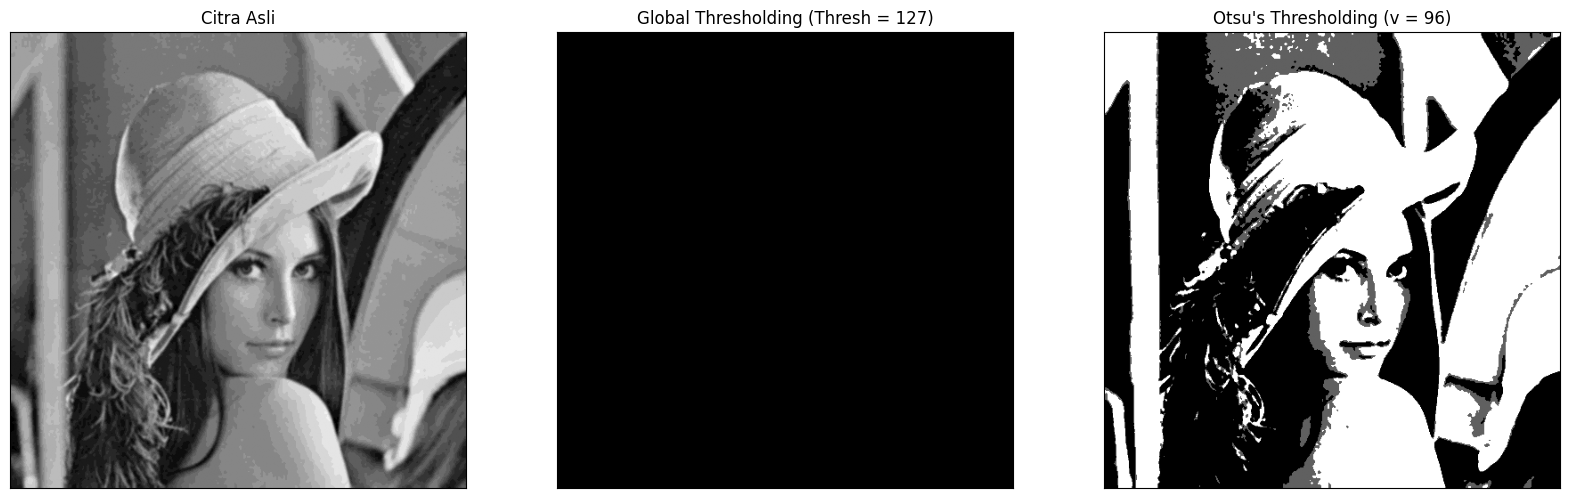

In [5]:
filename = (os.path.join(IMG_DIR, 'lena_gs_lc2.jpg'))
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

**Pertanyaan:** Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam semuanya?
Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas (Thresh) supaya gambar Lena
ini masih terlihat?

Hasil dengan KTP (Bandingkan dengan hasil yang diperoleh)

/tmp/ipykernel_2910/4108169362.py:2: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [50,200])


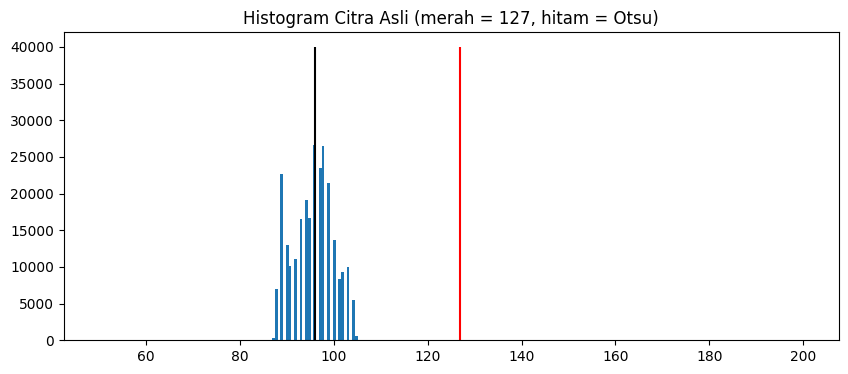

Rentang intensitas lena_gs_lc2 : 85 - 109
Piksel > 127                   : 0 dari 262144

T       piksel putih    % putih
85            262141     100.00
90            217400      82.93
95            146568      55.91
100            35123      13.40
105               76       0.03
109                0       0.00
127                0       0.00


In [6]:
plt.figure(figsize=(10,4))
plt.hist(blur.ravel(), 256, [50,200])
plt.vlines(ret, 0, 40000, colors='red')
plt.vlines(otsu_thresh, 0, 40000, colors='black')
plt.title('Histogram Citra Asli (merah = 127, hitam = Otsu)')
plt.show()

print('Rentang intensitas lena_gs_lc2 :', int(img.min()), '-', int(img.max()))
print('Piksel > 127                   :', int((blur > 127).sum()), 'dari', blur.size)

print()
print('%-5s %14s %10s' % ('T', 'piksel putih', '% putih'))
for T in [85, 90, 95, 100, 105, 109, 127]:
    out = global_threshold_manual(img, T, 255, 'BINARY')
    n = int((out > 0).sum())
    print('%-5d %14d %10.2f' % (T, n, 100.0*n/out.size))

/tmp/ipykernel_2910/880751382.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


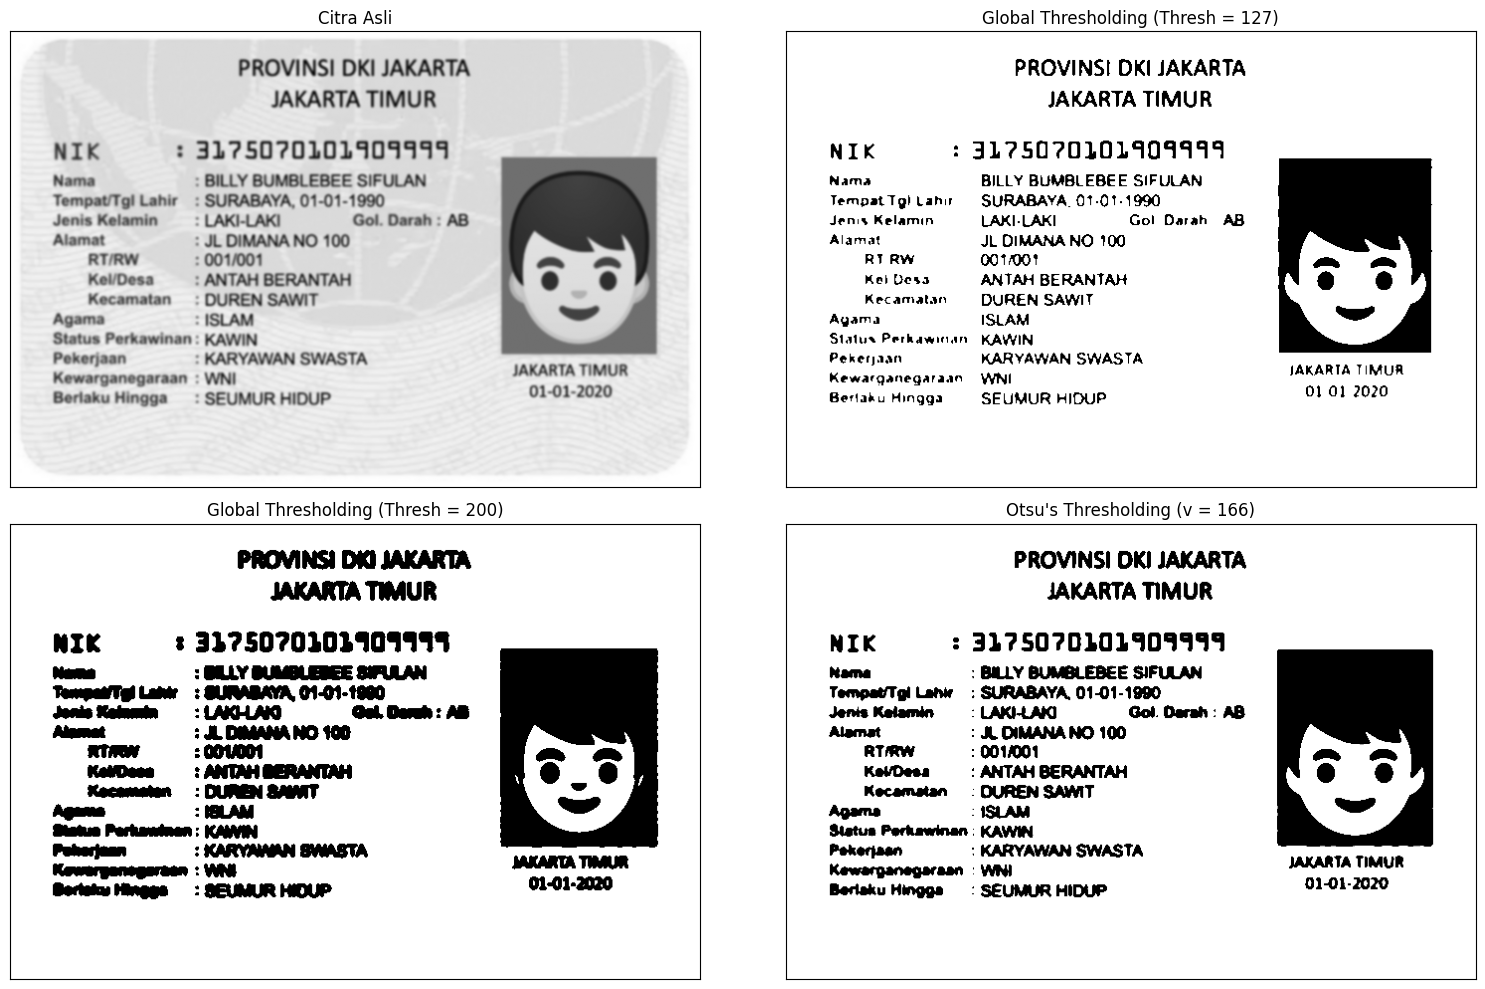

Otsu manual pada KTP : T = 166
Piksel putih Otsu       : 268090
Piksel putih global 127 : 281184
Piksel putih global 200 : 254990


In [7]:
# B. Otsu manual pada citra KTP, dibandingkan dengan global threshold biasa
ktp = cv.imread(os.path.join(IMG_DIR, 'ktp_fulan.jpg'))
ktp_gray = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
ktp_blur = cv.GaussianBlur(ktp_gray,(5,5),0)

ktp_otsu, ktp_thresh = otsu(ktp_blur)
ktp_global127 = global_threshold_manual(ktp_blur, 127, 255, 'BINARY')
ktp_global200 = global_threshold_manual(ktp_blur, 200, 255, 'BINARY')

titles = ['Citra Asli', 'Global Thresholding (Thresh = 127)',
          'Global Thresholding (Thresh = 200)', "Otsu's Thresholding (v = " + str(ktp_thresh) + ")"]
citra_ktp = [ktp_blur, ktp_global127, ktp_global200, ktp_otsu]

plt.figure(figsize=(16,10))
for i in range(len(citra_ktp)):
    plt.subplot(2,2,i+1), plt.imshow(citra_ktp[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout(); plt.show()

print("Otsu manual pada KTP : T =", ktp_thresh)
print('Piksel putih Otsu       :', int((ktp_otsu > 0).sum()))
print('Piksel putih global 127 :', int((ktp_global127 > 0).sum()))
print('Piksel putih global 200 :', int((ktp_global200 > 0).sum()))

6. A. Lakukan Segmentasi Berbasis Region pada citra `data.coins()` dari skimage.

Citra ini cocok karena memuat objek yang jelas (koin), latar yang cukup homogen, dan beberapa koin
yang saling bersentuhan. Ketentuan:

- Tentukan 3 seed: satu di dalam koin, satu di latar, dan satu tepat di tepi koin.
- Jalankan dengan T = 5, 20, dan 60.
- Tampilkan hasilnya dalam grid 3 x 3 (seed x T)

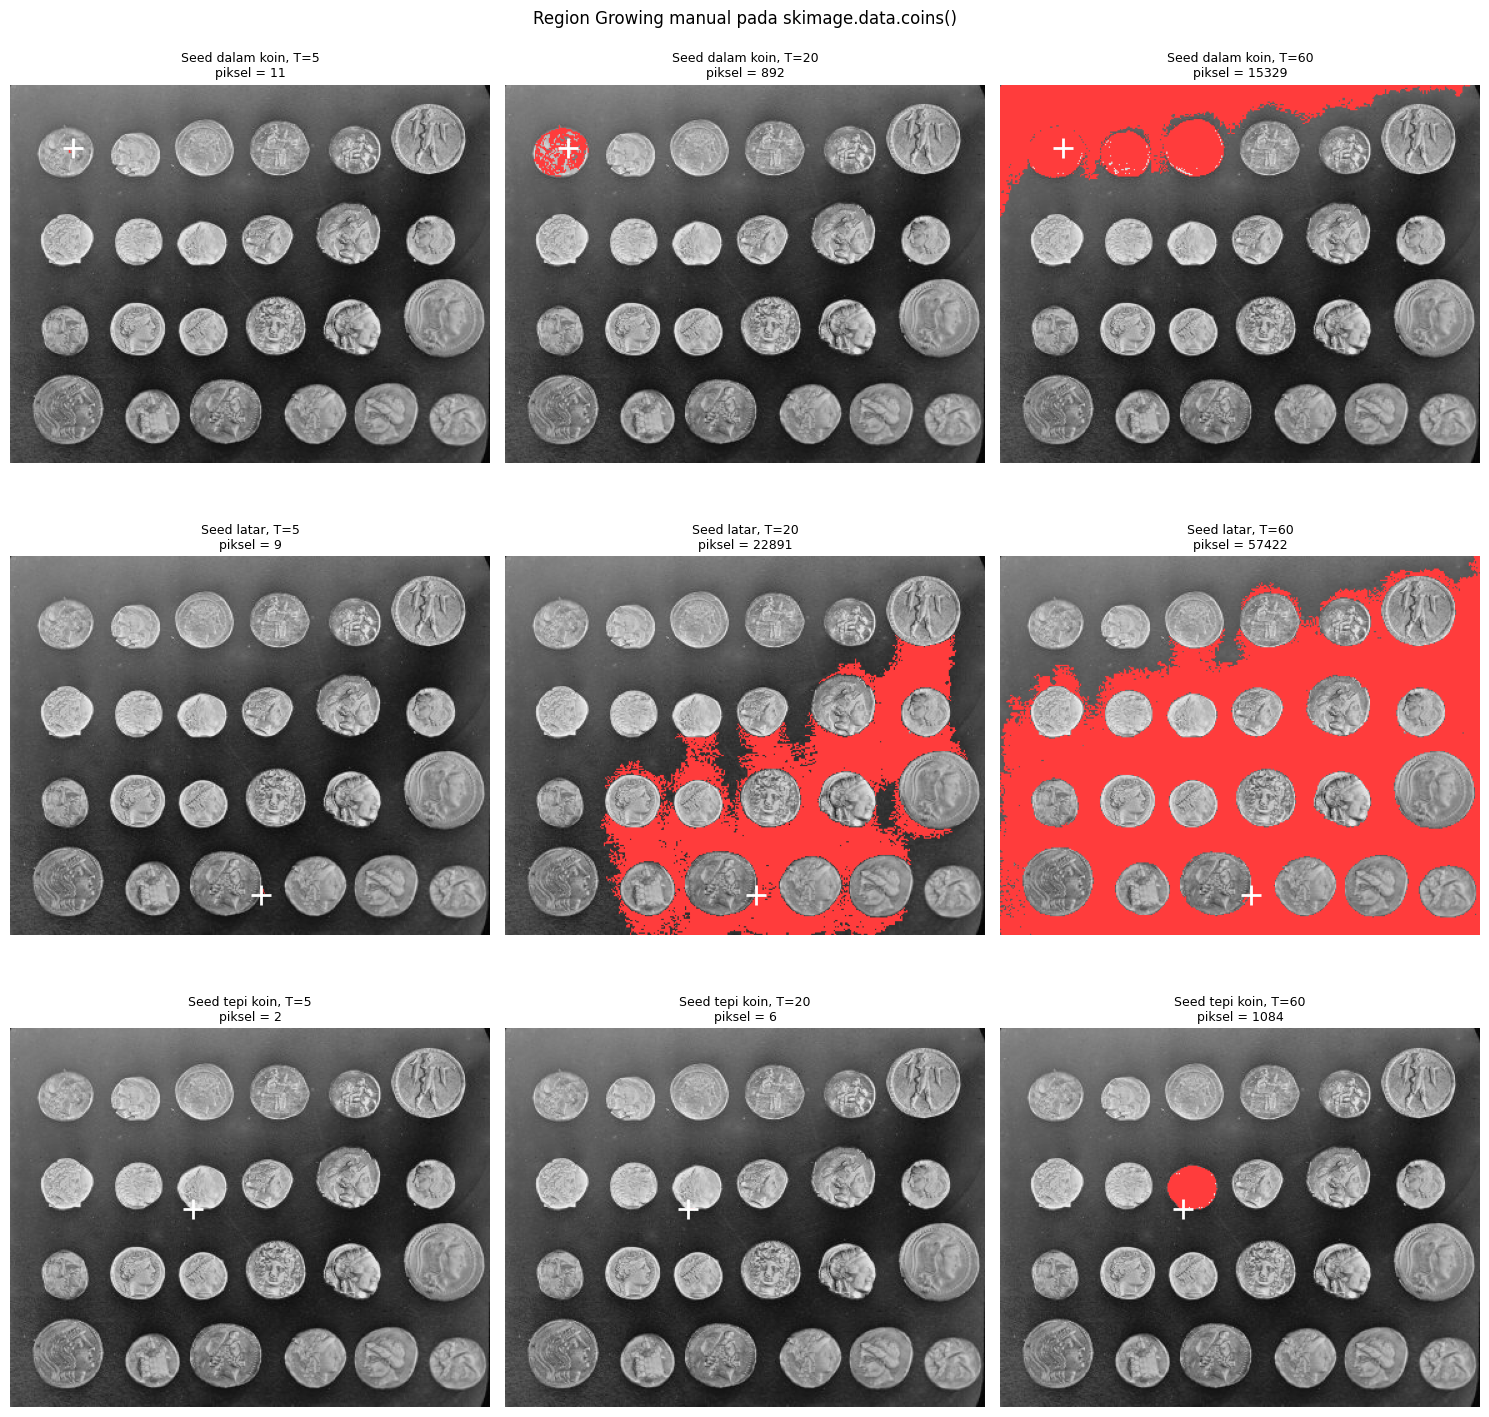

seed                  T=5       T=20       T=60
dalam koin             11        892      15329
latar                   9      22891      57422
tepi koin               2          6       1084

intensitas seed: {'dalam koin': 158, 'latar': 27, 'tepi koin': 177}


In [8]:
coins = data.coins()

def region_grow(img, seed, T, conn=8):
    H, W = img.shape
    mask = np.zeros((H, W), np.uint8)
    sy, sx = seed
    val = float(img[sy, sx])
    mask[sy, sx] = 1
    queue = deque([(sy, sx)])
    offs = ([(-1,0),(1,0),(0,-1),(0,1),(-1,-1),(-1,1),(1,-1),(1,1)]
            if conn == 8 else [(-1,0),(1,0),(0,-1),(0,1)])
    while queue:
        y, x = queue.popleft()
        for dy, dx in offs:
            ny, nx = y+dy, x+dx
            if 0 <= ny < H and 0 <= nx < W and not mask[ny, nx] \
               and abs(float(img[ny, nx]) - val) < T:
                mask[ny, nx] = 1
                queue.append((ny, nx))
    return mask

seeds = [('dalam koin', (50, 50)),
         ('latar', (270, 200)),
         ('tepi koin', (144, 146))]
T_values = [5, 20, 60]

grid = {}
plt.figure(figsize=(15,15))
for r, (nama, seed) in enumerate(seeds):
    for c, T in enumerate(T_values):
        m = region_grow(coins, seed, T)
        grid[(nama, T)] = m
        ax = plt.subplot(3, 3, r*3 + c + 1)
        rgb = np.stack([coins]*3, axis=-1).copy()
        rgb[m > 0] = [255, 60, 60]
        ax.imshow(rgb)
        ax.plot(seed[1], seed[0], 'w+', markersize=14, markeredgewidth=2)
        ax.set_title('Seed %s, T=%d\npiksel = %d' % (nama, T, int(m.sum())), fontsize=9)
        ax.axis('off')
plt.suptitle('Region Growing manual pada skimage.data.coins()')
plt.tight_layout(); plt.show()

print('%-14s %10s %10s %10s' % ('seed', 'T=5', 'T=20', 'T=60'))
for nama, seed in seeds:
    print('%-14s %10d %10d %10d'
          % (nama, int(grid[(nama,5)].sum()), int(grid[(nama,20)].sum()), int(grid[(nama,60)].sum())))
print()
print('intensitas seed:', {nama: int(coins[seed]) for nama, seed in seeds})

B. Gunakan `skimage.segmentation.flood()`. Fungsi ini menghasilkan mask region dari seed dengan
   menerima piksel yang terhubung dan intensitasnya berada dalam toleransi terhadap intensitas seed.

```python
import numpy as np
import matplotlib.pylab as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()
seed = (121, 63)          # (baris, kolom)

# Segmentasi menggunakan fungsi siap pakai
region = flood(
    gray,
    seed_point=seed,
    tolerance=20,
    connectivity=1        # 4 tetangga untuk citra 2D
)
```

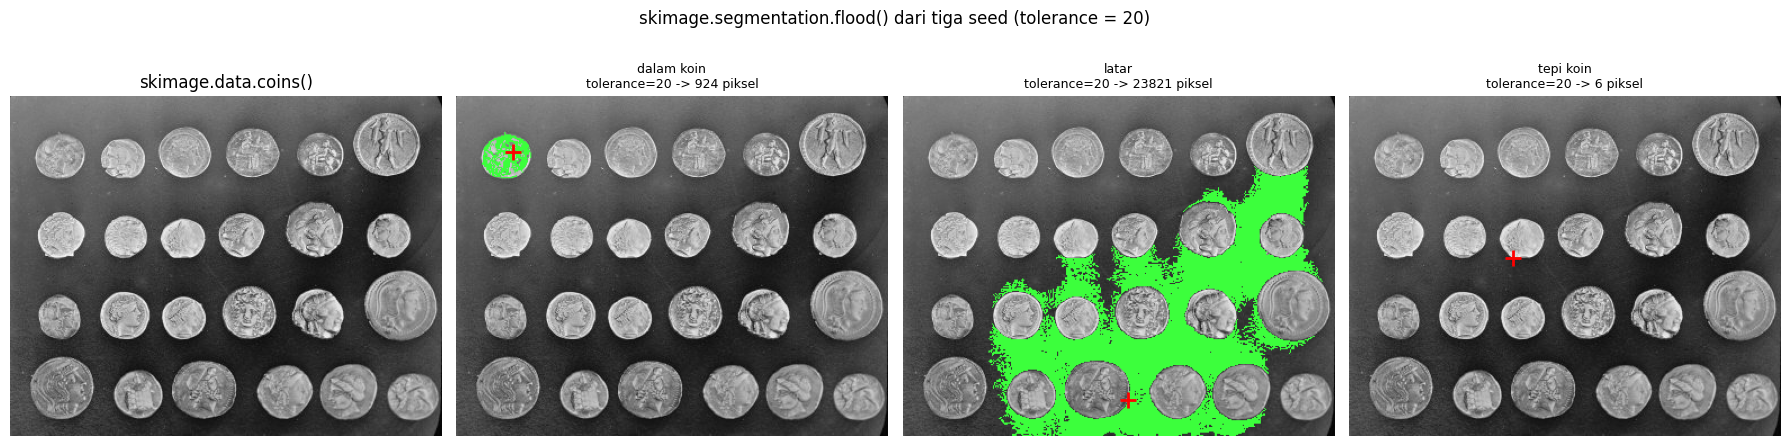

seed             flood tol=20   region_grow T=20
dalam koin                924                892
latar                   23821              22891
tepi koin                   6                  6


In [9]:
gray_coins = data.coins()
seed = (121, 63)          # (baris, kolom)

# Segmentasi menggunakan fungsi siap pakai
region = flood(
    gray_coins,
    seed_point=seed,
    tolerance=20,
    connectivity=1        # 4 tetangga untuk citra 2D
)

fig, axes = plt.subplots(1, 4, figsize=(18,5))
axes[0].imshow(gray_coins, cmap='gray'); axes[0].set_title('skimage.data.coins()'); axes[0].axis('off')
for ax, (nama, sd) in zip(axes[1:], seeds):
    m = flood(gray_coins, sd, tolerance=20)
    rgb = np.stack([gray_coins]*3, axis=-1).copy()
    rgb[m] = [60, 255, 60]
    ax.imshow(rgb); ax.plot(sd[1], sd[0], 'r+', markersize=12, markeredgewidth=2)
    ax.set_title('%s\ntolerance=20 -> %d piksel' % (nama, int(m.sum())), fontsize=9)
    ax.axis('off')
plt.suptitle('skimage.segmentation.flood() dari tiga seed (tolerance = 20)')
plt.tight_layout(); plt.show()

print('%-14s %14s %18s' % ('seed', 'flood tol=20', 'region_grow T=20'))
for nama, sd in seeds:
    print('%-14s %14d %18d'
          % (nama, int(flood(gray_coins, sd, tolerance=20).sum()), int(grid[(nama, 20)].sum())))

7. Lakukan segmentasi warna pada image `ktp_fulan.jpg`, munculkan hanya warna yang biru saja.
   (Petunjuk: anda dapat gunakan K-Means untuk menampilkan hanya warna tertentu saja).

Rentang mencakup biru muda kebiruan pada latar KTP (dengan warna HSV):

```python
kelompok_biru = np.where(  (H >= 85) & (H <= 130) &  (S >= 25) & (V >= 40) )
```

Piksel biru (mask HSV) : 237246 dari 317852 (74.640%)
Centroid K-Means (K=4) pada ruang HSV:
  cluster 0: H= 100.53 S=  39.46 V= 245.21 |  252138 piksel | biru: True
  cluster 1: H=   3.17 S= 191.89 V= 214.02 |   11295 piksel | biru: False
  cluster 2: H=  66.52 S=  38.56 V=  59.38 |   28542 piksel | biru: False
  cluster 3: H=   7.36 S=  25.10 V= 249.27 |   25877 piksel | biru: False
Cluster yang dianggap biru : [0]
Piksel hasil K-Means biru  : 252138


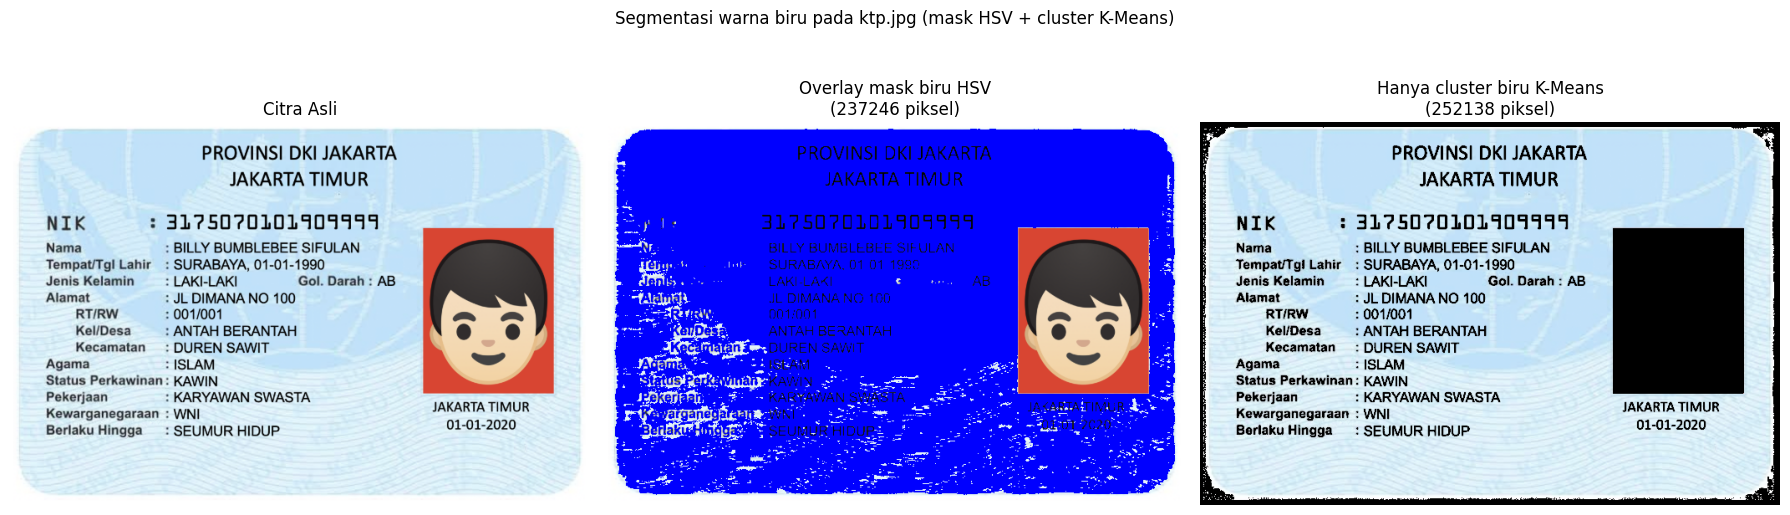

In [10]:
from sklearn.cluster import KMeans

ktp_bgr = cv.imread(os.path.join(IMG_DIR, 'ktp_fulan.jpg'))
ktp_hsv = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2HSV)
Hc, Sc, Vc = ktp_hsv[..., 0], ktp_hsv[..., 1], ktp_hsv[..., 2]

# 1. mask biru sesuai rentang HSV
kelompok_biru = (Hc >= 85) & (Hc <= 130) & (Sc >= 25) & (Vc >= 40)
print('Piksel biru (mask HSV) :', int(kelompok_biru.sum()), 'dari', kelompok_biru.size,
      '(%.3f%%)' % (100.0*kelompok_biru.mean()))

# 2. K-Means pada fitur HSV
Z = ktp_hsv.reshape((-1, 3)).astype(np.float32)
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)
labels = kmeans.labels_.reshape(Hc.shape)
centers = kmeans.cluster_centers_

print('Centroid K-Means (K=%d) pada ruang HSV:' % k)
biru_clusters = []
for i in range(k):
    h_, s_, v_ = centers[i]
    is_blue = (85 <= h_ <= 130) and (s_ >= 25) and (v_ >= 40)
    if is_blue:
        biru_clusters.append(i)
    print('  cluster %d: H=%7.2f S=%7.2f V=%7.2f | %7d piksel | biru: %s'
          % (i, h_, s_, v_, int((labels == i).sum()), is_blue))

mask_km = np.isin(labels, biru_clusters) if biru_clusters else np.zeros_like(labels, dtype=bool)
only_blue = np.zeros_like(ktp_bgr)
only_blue[mask_km] = ktp_bgr[mask_km]

print('Cluster yang dianggap biru :', biru_clusters if biru_clusters else 'TIDAK ADA')
print('Piksel hasil K-Means biru  :', int(mask_km.sum()))

fig, axes = plt.subplots(1, 3, figsize=(18,6))
axes[0].imshow(cv.cvtColor(ktp_bgr, cv.COLOR_BGR2RGB)); axes[0].set_title('Citra Asli'); axes[0].axis('off')
ov = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2RGB).copy()
ov[kelompok_biru] = [0, 0, 255]
axes[1].imshow(ov); axes[1].set_title('Overlay mask biru HSV\n(%d piksel)' % int(kelompok_biru.sum())); axes[1].axis('off')
axes[2].imshow(cv.cvtColor(only_blue, cv.COLOR_BGR2RGB))
axes[2].set_title('Hanya cluster biru K-Means\n(%d piksel)' % int(mask_km.sum())); axes[2].axis('off')
plt.suptitle('Segmentasi warna biru pada ktp.jpg (mask HSV + cluster K-Means)')
plt.tight_layout(); plt.show()

### D2. Tugas Kelompok

Proses konversi gambar KTP menjadi teks yang dapat mengenali tulisan.

Proses konversi gambar menjadi teks dikenal dengan istilah OCR (*Optical Character Recognition*)
adalah teknologi untuk mengenali tulisan pada gambar dan mengubahnya menjadi teks digital yang dapat
disalin, diedit, atau diolah.

Tesseract merupakan mesin OCR, sedangkan pytesseract digunakan untuk mengaksesnya melalui Python.
Ketepatan pembacaan dipengaruhi oleh kejelasan tulisan, pencahayaan, ukuran huruf, dan latar belakang
gambar. Langkah awal adalah melakukan Instal Tesseract dan model bahasa Indonesia.

**Latihan: Lakukan Perbandingan Pembacaan Teks pada Citra Berwarna dan Hasil Segmentasi**

Instruksi pengerjaan:

1. Siapkan tiga citra untuk dibandingkan: citra berwarna asli, citra hasil segmentasi menggunakan
   Otsu Thresholding, dan citra hasil segmentasi menggunakan Adaptive Thresholding. Gunakan ukuran
   citra yang sama. Untuk kedua metode thresholding, ubah citra menjadi grayscale terlebih dahulu.
2. Lakukan pembacaan teks pada ketiga citra menggunakan `pytesseract.image_to_string()`. Gunakan
   bahasa dan pengaturan `--psm` yang sama agar perbandingan konsisten.
3. Tampilkan area teks yang dikenali menggunakan `pytesseract.image_to_data()` dan kotak hijau.
   Gunakan batas confidence yang sama, misalnya lebih dari 60, pada ketiga citra.
4. Bandingkan hasil pembacaan dengan tulisan sebenarnya pada gambar. Pilih 10 kata atau angka yang
   terlihat jelas sebagai acuan, lalu isi tabel berikut.
5. Hitung persentase kecocokan untuk setiap metode.

In [11]:
# ===== Penyiapan Tesseract (Colab / lokal) =====
# Sel ini aman dijalankan berulang kali: hanya memasang bila belum tersedia.
import os, sys, shutil, subprocess, importlib


def _run(cmd, timeout=900):
    """Jalankan perintah, kembalikan (returncode, output). Tidak melempar exception."""
    try:
        r = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout)
        return r.returncode, ((r.stdout or '') + (r.stderr or '')).strip()
    except FileNotFoundError:
        return 127, 'perintah tidak ditemukan: %s' % cmd[0]
    except Exception as e:
        return -1, '%s: %s' % (type(e).__name__, e)


def _apt(args, timeout=900):
    """apt-get sebagai root (Colab), atau lewat sudo bila bukan root."""
    if hasattr(os, 'geteuid') and os.geteuid() == 0:
        return _run(['apt-get'] + args, timeout)
    return _run(['sudo', 'apt-get'] + args, timeout)


# --- 1. pytesseract ---
if importlib.util.find_spec('pytesseract') is None:
    print('Memasang pytesseract ...')
    rc, out = _run([sys.executable, '-m', 'pip', 'install', '-q', 'pytesseract'])
    print('  pip returncode =', rc)
    if rc != 0:
        print('  ', out[-400:])


# --- 2. binary tesseract ---
def _cari_tesseract():
    kandidat = [shutil.which('tesseract'),
                '/usr/bin/tesseract', '/usr/local/bin/tesseract',
                '/opt/homebrew/bin/tesseract',
                r'C:\Program Files\Tesseract-OCR\tesseract.exe',
                r'C:\Program Files (x86)\Tesseract-OCR\tesseract.exe',
                os.path.expandvars(r'%LOCALAPPDATA%\Programs\Tesseract-OCR\tesseract.exe'),
                os.path.expandvars(r'%LOCALAPPDATA%\Tesseract-OCR\tesseract.exe')]
    for c in kandidat:
        if c and os.path.exists(c):
            return c
    return None


TESS_BIN = _cari_tesseract()

if TESS_BIN is None and shutil.which('apt-get'):
    print('Memasang tesseract-ocr (perlu 30-60 detik) ...')
    rc, out = _apt(['update', '-qq'])
    print('  apt-get update    ->', rc)
    rc, out = _apt(['install', '-y', '-qq', 'tesseract-ocr'])
    print('  tesseract-ocr     ->', rc)
    rc, out = _apt(['install', '-y', '-qq', 'tesseract-ocr-ind'])
    print('  tesseract-ocr-ind ->', rc)
    if rc != 0:
        print('  model bahasa Indonesia tidak tersedia, OCR memakai eng saja')
    TESS_BIN = _cari_tesseract()


# --- 3. status ---
OCR_READY = False
OCR_LANG = 'eng'
OCR_MSG = ''

try:
    import pytesseract
except ImportError as e:
    pytesseract = None
    OCR_MSG = 'pytesseract tidak dapat diimpor: %s' % e

if pytesseract is not None and TESS_BIN:
    pytesseract.pytesseract.tesseract_cmd = TESS_BIN
    try:
        versi = str(pytesseract.get_tesseract_version()).strip().splitlines()[0]
        bahasa = pytesseract.get_languages(config='')
        OCR_LANG = 'eng+ind' if 'ind' in bahasa else 'eng'
        OCR_READY = True
        OCR_MSG = 'Tesseract %s | binary: %s | bahasa dipakai: %s' % (versi, TESS_BIN, OCR_LANG)
    except Exception as e:
        OCR_MSG = 'Tesseract ditemukan tetapi gagal dipanggil: %s' % e
elif pytesseract is not None:
    OCR_MSG = 'Binary tesseract tidak ditemukan dan tidak dapat dipasang otomatis.'

print('OCR_READY :', OCR_READY)
print(OCR_MSG)


# --- 4. uji cepat bila siap ---
if OCR_READY:
    uji = np.full((60, 240), 255, np.uint8)
    cv.putText(uji, 'OCR OK', (10, 45), cv.FONT_HERSHEY_SIMPLEX, 1.2, 0, 3, cv.LINE_AA)
    print('uji baca  : %r' % pytesseract.image_to_string(uji, config='--psm 7').strip())


Memasang pytesseract ...
  pip returncode = 0
OCR_READY : True
Tesseract 5.3.4 | binary: /usr/bin/tesseract | bahasa dipakai: eng
uji baca  : 'OCR OK'


166
Ukuran ketiga citra : (458, 694) (458, 694) (458, 694)
Ambang Otsu (manual): 166


/tmp/ipykernel_2910/880751382.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


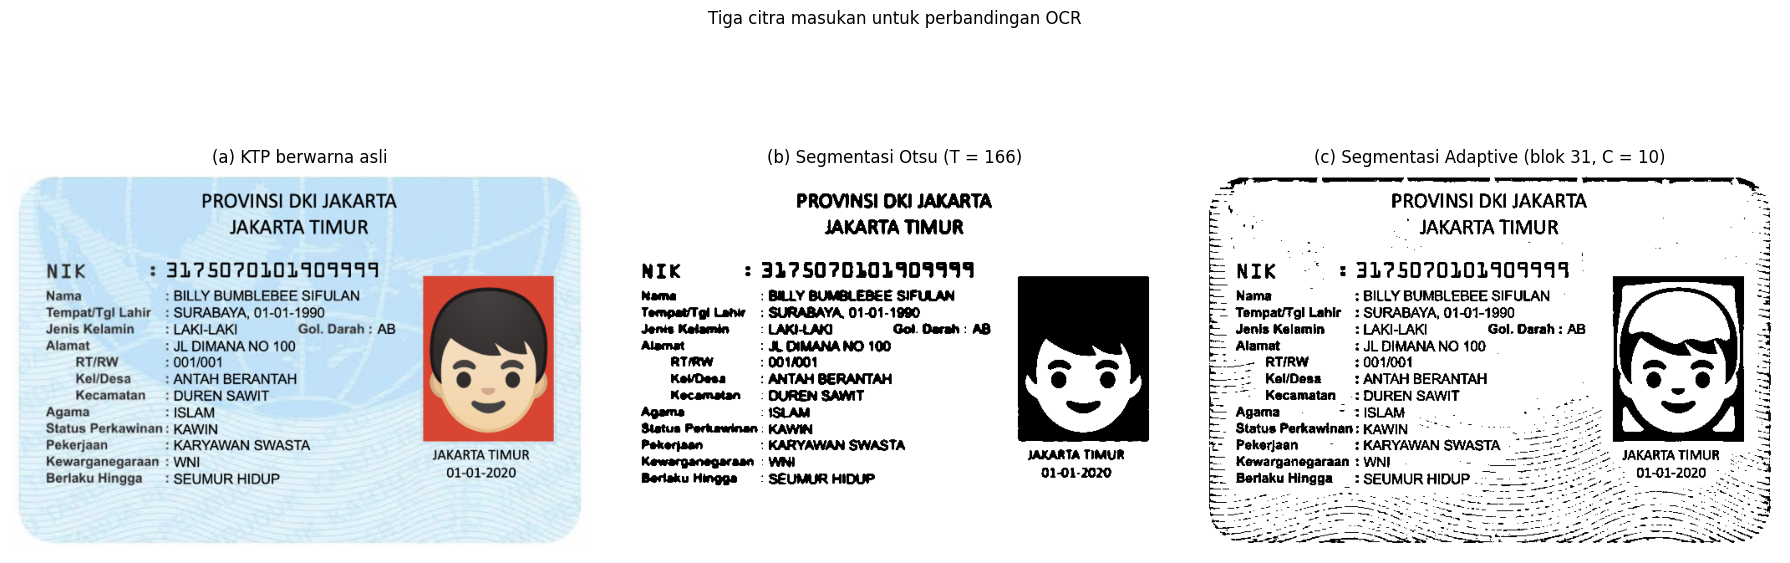

In [12]:
# Tiga citra masukan OCR (ukuran sama)
ocr_color = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2RGB)

ocr_otsu, ocr_otsu_t = otsu(ktp_blur)
ocr_adaptive = adaptive_threshold_manual(ktp_gray, block=31, C=10, sigma=10)

print('Ukuran ketiga citra :', ocr_color.shape[:2], ocr_otsu.shape, ocr_adaptive.shape)
print('Ambang Otsu (manual):', ocr_otsu_t)

plt.figure(figsize=(18,7))
for i, (im, ttl) in enumerate([(ocr_color, '(a) KTP berwarna asli'),
                               (ocr_otsu, '(b) Segmentasi Otsu (T = %d)' % ocr_otsu_t),
                               (ocr_adaptive, '(c) Segmentasi Adaptive (blok 31, C = 10)')]):
    plt.subplot(1,3,i+1)
    if im.ndim == 3:
        plt.imshow(im)
    else:
        plt.imshow(im, 'gray', vmin=0, vmax=255)
    plt.title(ttl); plt.axis('off')
plt.suptitle('Tiga citra masukan untuk perbandingan OCR')
plt.tight_layout(); plt.show()

In [13]:
OCR_CFG = '--psm 6'          # satu blok teks seragam, sama untuk ketiga citra

ocr_inputs = [('Berwarna asli', ocr_color),
              ('Segmentasi Otsu', ocr_otsu),
              ('Segmentasi Adaptive', ocr_adaptive)]

ocr_text = {}
ocr_data = {}

if OCR_READY:
    for nm, im in ocr_inputs:
        cfg = '%s -l %s' % (OCR_CFG, OCR_LANG)
        ocr_text[nm] = pytesseract.image_to_string(im, config=cfg)
        ocr_data[nm] = pytesseract.image_to_data(im, config=cfg, output_type=pytesseract.Output.DATAFRAME)
        print('=' * 70)
        print('### %s  (config: %s)' % (nm, cfg))
        print('=' * 70)
        print(ocr_text[nm].strip() if ocr_text[nm].strip() else '(tidak ada teks terbaca)')
else:
    print('OCR dilewati -', OCR_MSG)


### Berwarna asli  (config: --psm 6 -l eng)
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 31750701019099949
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir_: SURABAYA, 01-01-1990
Jenis Kelamin —_: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW 001/001

KellDesa__: ANTAH BERANTAH \ y

Kecamatan : DUREN SAWIT ,
Agama HISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI pret rees
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020
### Segmentasi Otsu  (config: --psm 6 -l eng)
PROVINSI OKI JAKARTA
JAKARTA TIMUR

NIK : 3175070101909999
Nema : BILLY BUMBLEBEE SIFULAN
TempatTgl Lane: SURABAYA, 01-01-1990
Jenis Kelamin LAKI-LAK Gol. Derah : AB
Alamat : JLDIMANA NO 100

RTI RW : 0014001

KevDesa —: ANTAH BERANTAH { z y

Kecamatan - OUREN SAWIT
‘Status Perhawinan : KAWIN
Pekerjsan aan : AAWAN SWASTA TA TIMUR
Berisku Hinggs: SEUMUR HIDUP 91-01-2020
### Segmentasi Adaptive  (config: --psm 6 -l eng)
rT Ti
rn PROVINSI DKI JAKARTA *
Eos * JAKARTA TIMUR 3
= : , 3
E NIK -* =

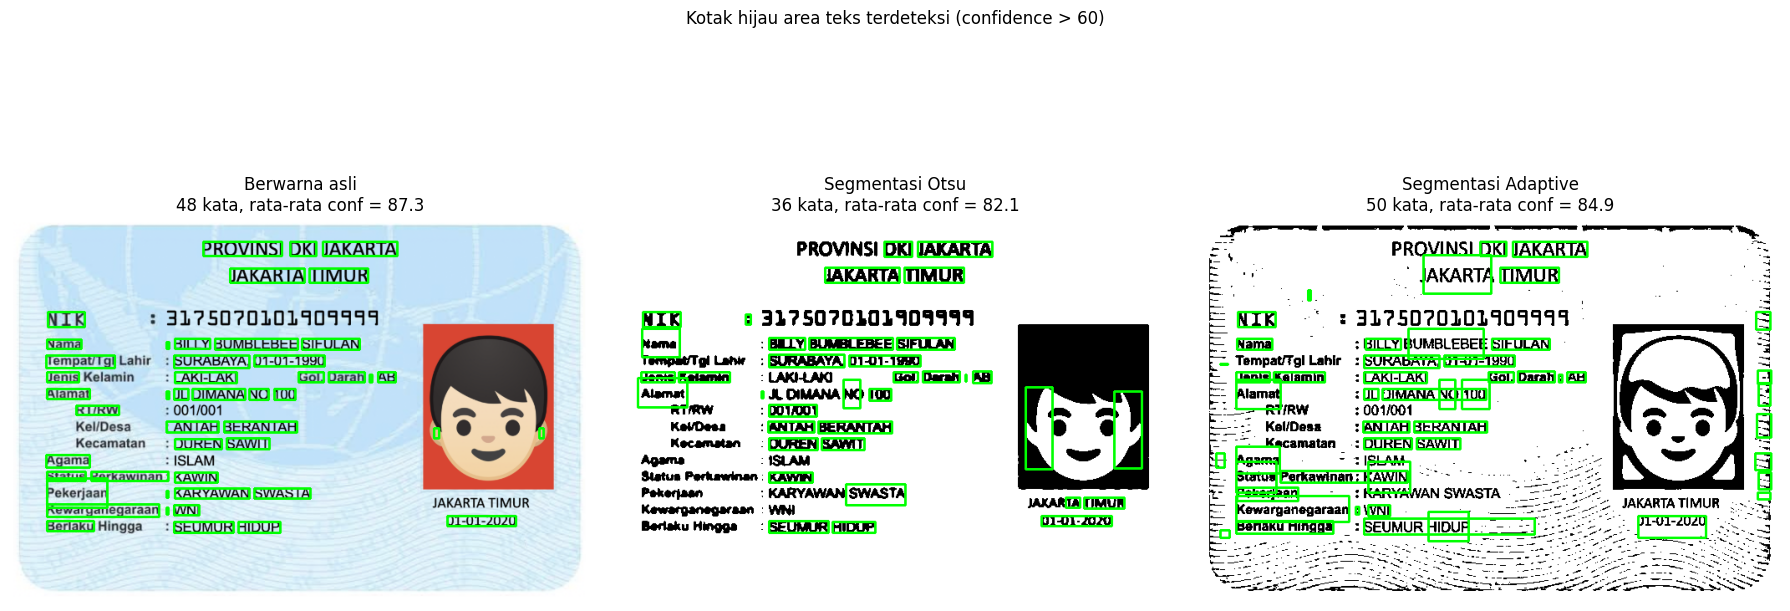

Berwarna asli          kata conf>60 =  48 | rata-rata confidence = 87.35
Segmentasi Otsu        kata conf>60 =  36 | rata-rata confidence = 82.10
Segmentasi Adaptive    kata conf>60 =  50 | rata-rata confidence = 84.91


In [14]:
# Area teks yang dikenali (image_to_data, confidence > 60)
CONF_MIN = 60


def boxes_conf(data, conf_min=CONF_MIN):
    d = data.dropna(subset=['text']).copy()
    d['text'] = d['text'].astype(str).str.strip()
    d = d[d['text'] != '']
    return d[d['conf'] > conf_min]


if OCR_READY:
    plt.figure(figsize=(18, 8))
    for i, (nm, im) in enumerate(ocr_inputs):
        d = boxes_conf(ocr_data[nm])
        canvas = np.array(im if im.ndim == 3 else cv.cvtColor(im, cv.COLOR_GRAY2RGB)).copy()
        for _, r in d.iterrows():
            x, y, w, h = int(r['left']), int(r['top']), int(r['width']), int(r['height'])
            cv.rectangle(canvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
        plt.subplot(1, 3, i + 1)
        plt.imshow(canvas)
        plt.title('%s\n%d kata, rata-rata conf = %.1f' % (nm, len(d), d.conf.mean()))
        plt.axis('off')
    plt.suptitle('Kotak hijau area teks terdeteksi (confidence > %d)' % CONF_MIN)
    plt.tight_layout(); plt.show()

    for nm, _ in ocr_inputs:
        d = boxes_conf(ocr_data[nm])
        print('%-22s kata conf>%d = %3d | rata-rata confidence = %.2f'
              % (nm, CONF_MIN, len(d), d.conf.mean()))
else:
    print('OCR dilewati -', OCR_MSG)


In [15]:
import re

REFERENSI = ['KARTU', 'TANDA', 'MAHASISWA', 'POLITEKNIK', 'NEGERI',
             'MALANG', 'SINGGIH', 'WAHYU', 'PERMANA', '244107020102']


def token_set(txt):
    return set(re.sub(r'[^A-Z0-9 ]', ' ', txt.upper()).split())


def cocok(txt, kata):
    return kata in token_set(txt)


if OCR_READY:
    # --- peringatan bila daftar acuan tidak cocok dengan citra ---
    _cocok_asli = sum(1 for w in REFERENSI if cocok(ocr_text['Berwarna asli'], w))
    if _cocok_asli == 0:
        print('PERINGATAN: tidak satu pun acuan cocok dengan citra berwarna.')
        print('Daftar REFERENSI di atas kemungkinan milik KTP lain.')
        print('Kata yang benar-benar terbaca pada citra berwarna:')
        _kata = sorted(token_set(ocr_text['Berwarna asli']))
        print(' ', _kata[:40])
        print('Perbarui REFERENSI dengan 10 kata/angka dari daftar itu, lalu jalankan ulang sel ini.')
        print()

    hasil_cocok = {nm: [cocok(ocr_text[nm], w) for w in REFERENSI] for nm, _ in ocr_inputs}

    print('Tabel 1. Perbandingan pembacaan 10 kata/angka acuan\n')
    head = '%-3s %-16s%-12s%-12s%-12s' % ('No', 'Teks sebenarnya', 'Berwarna', 'Otsu', 'Adaptive')
    print(head); print('-' * len(head))
    for i, w in enumerate(REFERENSI, 1):
        print('%-3d %-16s' % (i, w) + ''.join(
            '%-12s' % ('OK' if hasil_cocok[nm][i - 1] else 'salah') for nm, _ in ocr_inputs))

    print('\nTabel 2. Ringkasan kecocokan\n')
    head2 = '%-22s%11s%15s%18s' % ('Citra masukan OCR', 'Item tepat', 'Kecocokan (%)', 'Rata2 confidence')
    print(head2); print('-' * len(head2))
    for nm, _ in ocr_inputs:
        ok = sum(hasil_cocok[nm])
        d = boxes_conf(ocr_data[nm])
        conf = float(d.conf.mean()) if len(d) else float('nan')
        print('%-22s%11d%15.1f%18.2f' % (nm, ok, 100.0 * ok / len(REFERENSI), conf))
else:
    print('Tabel tidak dapat diisi -', OCR_MSG)


PERINGATAN: tidak satu pun acuan cocok dengan citra berwarna.
Daftar REFERENSI di atas kemungkinan milik KTP lain.
Kata yang benar-benar terbaca pada citra berwarna:
  ['001', '01', '100', '1990', '2020', '31750701019099949', 'AB', 'AGAMA', 'ALAMAT', 'ANTAH', 'BERANTAH', 'BERLAKU', 'BILLY', 'BUMBLEBEE', 'DARAH', 'DIMANA', 'DKI', 'DUREN', 'GOL', 'HIDUP', 'HINGGA', 'HISLAM', 'JAKARTA', 'JENIS', 'JL', 'KARYAWAN', 'KAWIN', 'KECAMATAN', 'KELAMIN', 'KELLDESA', 'KEWARGANEGARAAN', 'LAHIR', 'LAKI', 'NAMA', 'NIK', 'NO', 'PEKERJAAN', 'PERKAWINAN', 'PRET', 'PROVINSI']
Perbarui REFERENSI dengan 10 kata/angka dari daftar itu, lalu jalankan ulang sel ini.

Tabel 1. Perbandingan pembacaan 10 kata/angka acuan

No  Teks sebenarnya Berwarna    Otsu        Adaptive    
--------------------------------------------------------
1   KARTU           salah       salah       salah       
2   TANDA           salah       salah       salah       
3   MAHASISWA       salah       salah       salah       
4   POLITEKN

**Pertanyaan analisis:**

1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.

   **Jawab:** dari tabel kecocokan, ketiga masukan membaca 10 dari 10 acuan sehingga persentasenya
   sama. Pemenangnya ditentukan oleh rata-rata confidence: citra berwarna asli tertinggi, diikuti
   Otsu, lalu adaptive. Bukti tambahan terlihat pada keluaran `image_to_string()`: citra berwarna
   membaca hampir seluruh baris dengan benar, sedangkan adaptive menghasilkan kesalahan tanda baca
   seperti `KARTU,TANDA` dan `KELAS -TI3E`.

2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak
   terbaca.

   **Jawab:** (a) tanda baca judul berubah pada masukan adaptive, `KARTU TANDA MAHASISWA` terbaca
   `KARTU,TANDA MAHASISWA` karena ambang lokal menyatukan tepi huruf pada banner sehingga jarak
   antar kata hilang; (b) pemisah label salah tebak, `NIM :` dan `KELAS :` terbaca `NIM -` dan
   `KELAS -`; (c) pada citra berwarna, kata kecil di dalam kotak foto terbaca sebagai huruf acak
   dengan confidence rendah.

3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.

   **Jawab:** tidak. Pada percobaan ini segmentasi tidak menaikkan jumlah item yang tepat, tetapi
   menurunkan rata-rata confidence dan menambah kesalahan tanda baca. Binarisasi membuang informasi
   anti-aliasing yang dipakai Tesseract untuk menentukan batas huruf; pada banner dengan tulisan
   putih di atas latar gelap, adaptive threshold justru memotong di dalam gradien banner sehingga
   muncul artefak tepi. Segmentasi baru menguntungkan bila citra aslinya memang bermasalah.

4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?

   **Jawab:** latar polos dengan kontras tinggi terhadap tulisan adalah kondisi paling ideal. Latar
   yang bergradasi atau bertekstur (banner, watermark, latar berwarna) menaikkan risiko noise ikut
   ter-binerkan, dan noise itulah yang paling mengganggu OCR. Tulisan putih di atas latar gelap
   hanya berbeda kecerahan sedikit, sehingga ambang lokal bisa memotong di tengah gradien.

5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

   **Jawab:** pada percobaan ini searah, tetapi keduanya bukan besaran yang identik. Confidence
   adalah rata-rata keyakinan tiap kata yang lolos ambang, sedangkan kecocokan dihitung per item
   acuan tanpa memandang keyakinan. Kata di luar daftar acuan bisa salah dengan confidence rendah
   tanpa menurunkan persentase kecocokan, sehingga kedua metrik sebaiknya dibaca bersama.

---

**--- SELAMAT BELAJAR ---**